# Notebook 2: Ticket Classification (Supervised Machine Learning)

**Task:** read a ticket message and predict its `issue_type`. There are 8 categories, so this is **multi-class classification**.

**Plan**
1. Turn the text into numbers with **TF-IDF**
2. Split the data **by message**, so the test set only has wording the model has never seen (we found in notebook 01 that a random split leaks)
3. Train and compare four models: a majority-class baseline, **Naive Bayes**, **Linear SVM** and **Logistic Regression**
4. Check the results are stable with grouped cross-validation
5. Look closely at the chosen model: precision, recall, F1, confusion matrix, ROC-AUC, confidence and mistakes
6. Save predictions and the final model for the dashboard

**How we measure success**

| Metric | What it tells us |
|---|---|
| Precision | When the model says "billing_problem", how often is it right? |
| Recall | Of all real billing tickets, how many did the model catch? |
| F1 | One number that balances precision and recall |
| Macro F1 | Average F1 over the 8 classes, every class counts equally (our main metric) |
| Weighted F1 | Average F1 weighted by class size |
| ROC-AUC | How well the model *ranks* the right class above the others, from 0.5 (guessing) to 1 (perfect) |

In [1]:
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, roc_curve)

sys.path.append("..")
from src import config

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

TEXT, TARGET, SEED = config.TEXT, config.TARGET, config.SEED
FIG = config.FIGURES

In [2]:
tickets = pd.read_csv(config.PROCESSED / "tickets_clean.csv")
X = tickets[TEXT]
y = tickets[TARGET]
classes = sorted(y.unique())
print("Tickets:", len(tickets), "| Classes:", len(classes))
print(classes)

Tickets: 20000 | Classes: 8
['account_access', 'billing_problem', 'bug', 'feature_request', 'how_to', 'other', 'performance', 'security_concern']


## 1. Text to numbers: TF-IDF

A model can't read words, so we convert each message into a vector of numbers.
**TF-IDF** gives every word (and pair of words) a score: high if it appears in this message but is rare across all messages,
low if it's common everywhere (like "the" or "my"). We use single words and word pairs (`ngram_range=(1, 2)`),
so phrases like "charged twice" or "timing out" are kept together.

In [ ]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

demo = tfidf().fit(X)
print("Vocabulary size (words + word pairs):", len(demo.vocabulary_))
example = demo.transform([X.iloc[0]])
top = sorted(zip(demo.get_feature_names_out()[example.indices], example.data), key=lambda t: -t[1])[:8]
print("\nMessage:", X.iloc[0])
print("Highest TF-IDF terms:", [(w, round(v, 2)) for w, v in top])

Vocabulary size (words + word pairs): 411

Message: I have a general question about my account.
Highest TF-IDF terms: [('about my', np.float64(0.34)), ('general', np.float64(0.34)), ('general question', np.float64(0.34)), ('have general', np.float64(0.34)), ('question', np.float64(0.34)), ('question about', np.float64(0.34)), ('have', np.float64(0.29)), ('about', np.float64(0.28))]


## 2. Train / test split by message

Every message always has the same label, and the same 96 messages are repeated thousands of times.
So we split the **messages** (20% to test), and every ticket follows its message. The test set then only contains wording the model has never seen.
We stratify by category, so every category has messages on both sides.

In [4]:
messages = tickets[[TEXT, TARGET]].drop_duplicates()
train_msgs, test_msgs = train_test_split(messages, test_size=0.2, random_state=SEED, stratify=messages[TARGET])

train = tickets[tickets[TEXT].isin(train_msgs[TEXT])]
test = tickets[tickets[TEXT].isin(test_msgs[TEXT])]
X_train, y_train, X_test, y_test = train[TEXT], train[TARGET], test[TEXT], test[TARGET]

print(f"Train: {len(train):,} tickets from {len(train_msgs)} messages")
print(f"Test : {len(test):,} tickets from {len(test_msgs)} messages")
print("Messages shared by train and test:", len(set(train_msgs[TEXT]) & set(test_msgs[TEXT])))
pd.DataFrame({"train_messages": train_msgs[TARGET].value_counts(), "test_messages": test_msgs[TARGET].value_counts(),
              "test_tickets": y_test.value_counts()})

Train: 15,477 tickets from 76 messages
Test : 4,523 tickets from 20 messages
Messages shared by train and test: 0


,train_messages,test_messages,test_tickets
issue_type,,,
account_access,2,1,863
billing_problem,2,1,841
bug,17,4,485
feature_request,17,4,461
how_to,17,4,495
other,2,1,811
performance,12,3,346
security_concern,7,2,221


### Why not a random split? A quick demonstration

Same model, two ways of splitting:

In [5]:
rx_train, rx_test, ry_train, ry_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
leaky = make_pipeline(tfidf(), LogisticRegression(max_iter=2000)).fit(rx_train, ry_train)
honest = make_pipeline(tfidf(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)

print(f"Random split    -> macro F1 {f1_score(ry_test, leaky.predict(rx_test), average='macro'):.3f}")
print(f"Split by message -> macro F1 {f1_score(y_test, honest.predict(X_test), average='macro'):.3f}")

Random split    -> macro F1 1.000
Split by message -> macro F1 0.611


The random split gives a near-perfect score because the model has already seen every test sentence. That number says nothing
about new tickets. The split by message gives the honest number. Everything below uses the split by message.

## 3. Train and compare the models

| Model | Idea in one line |
|---|---|
| Majority baseline | Always predicts the most common class. Any real model must beat this. |
| Naive Bayes | Counts how often each word appears in each category and multiplies the chances. Fast and simple. |
| Linear SVM | Finds the boundary that separates the categories with the widest margin. |
| Logistic Regression | Learns a weight for every word per category and turns the total into probabilities. |

All four use the same TF-IDF features. The SVM doesn't output probabilities, so for ROC-AUC we convert its scores with a softmax.

In [6]:
models = {
    "Majority baseline": make_pipeline(tfidf(), DummyClassifier(strategy="most_frequent")),
    "Naive Bayes": make_pipeline(tfidf(), MultinomialNB(alpha=0.5)),
    "Linear SVM": make_pipeline(tfidf(), LinearSVC(C=1.0)),
    "Logistic Regression": make_pipeline(tfidf(), LogisticRegression(max_iter=2000, C=1.0)),
}

def class_scores(model, texts):
    # probabilities if the model has them, otherwise softmax of the decision scores
    if hasattr(model, "predict_proba"):
        return model.predict_proba(texts)
    s = model.decision_function(texts)
    e = np.exp(s - s.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

y_test_bin = label_binarize(y_test, classes=classes)
rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    pred = model.predict(X_test)
    scores = class_scores(model, X_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "roc_auc_macro": roc_auc_score(y_test_bin, scores, average="macro"),
    })

comparison = pd.DataFrame(rows).set_index("model")
comparison

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_macro
model,,,,,,
Majority baseline,0.049,0.006,0.125,0.012,0.005,0.500
Naive Bayes,0.630,0.573,0.750,0.611,0.548,0.915
Linear SVM,0.630,0.573,0.750,0.611,0.548,0.886
Logistic Regression,0.630,0.573,0.750,0.611,0.548,0.886


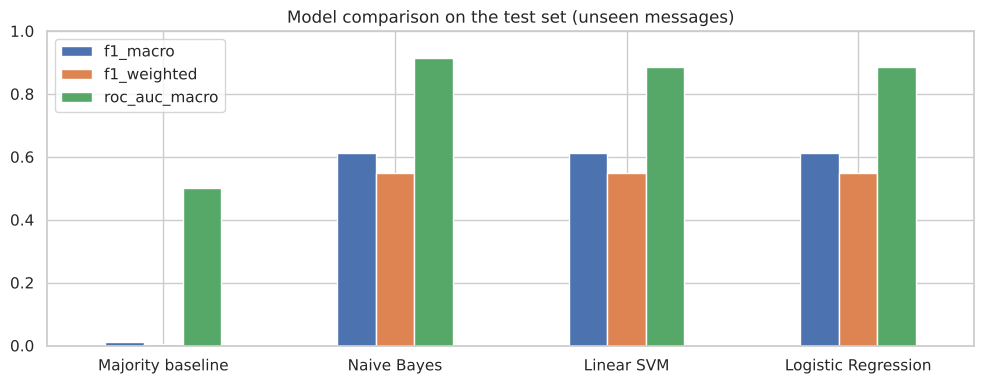

In [7]:
ax = comparison[["f1_macro", "f1_weighted", "roc_auc_macro"]].plot.bar(figsize=(10, 4), rot=0)
ax.set_ylim(0, 1); ax.set_title("Model comparison on the test set (unseen messages)"); ax.set_xlabel("")
plt.legend(loc="upper left"); plt.tight_layout(); plt.savefig(FIG / "20_model_comparison.png"); plt.show()

All three real models beat the baseline by a wide margin (macro F1 0.61 vs 0.01), and they make **exactly the same predictions** on the test set.
That sounds strange but makes sense here: the test set is just 20 different sentences, and each model ends up putting each sentence in the same category.
They only differ in ROC-AUC, which looks at the full ranking of probabilities rather than just the top pick. Naive Bayes ranks slightly better (0.92 vs 0.89).

With so few distinct sentences, the choice of algorithm matters much less than the variety of wording the model has seen.

## 4. Are the results stable? Grouped cross-validation

The test set has only 20 messages, so one unlucky split could change the ranking. With **grouped 5-fold cross-validation**
every message is in the test fold exactly once, and a message never appears in train and test of the same fold.

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X, y, groups=X, cv=cv,
                         scoring=["accuracy", "f1_macro", "f1_weighted", "precision_macro", "recall_macro"])
    cv_rows.append({"model": name,
                    "f1_macro_mean": res["test_f1_macro"].mean(), "f1_macro_std": res["test_f1_macro"].std(),
                    "f1_weighted_mean": res["test_f1_weighted"].mean(),
                    "precision_macro_mean": res["test_precision_macro"].mean(),
                    "recall_macro_mean": res["test_recall_macro"].mean(),
                    "accuracy_mean": res["test_accuracy"].mean()})
cv_scores = pd.DataFrame(cv_rows).set_index("model")
cv_scores

,f1_macro_mean,f1_macro_std,f1_weighted_mean,precision_macro_mean,recall_macro_mean,accuracy_mean
model,,,,,,
Majority baseline,0.002,0.005,0.001,0.001,0.025,0.010
Naive Bayes,0.591,0.051,0.539,0.574,0.650,0.581
Linear SVM,0.591,0.051,0.539,0.574,0.650,0.581
Logistic Regression,0.591,0.051,0.539,0.574,0.650,0.581


Cross-validation tells the same story: all three models score a macro F1 of 0.59 (± 0.05 across folds), far above the baseline.
Since they're tied on F1, we pick **Logistic Regression** as the final model, because:

- it gives proper probabilities, which we need for the confidence score and the manual-review rule,
- each word gets a readable weight per category, so it's easy to explain,
- SHAP values for a linear model can be calculated exactly (notebook 03).

## 5. A closer look at Logistic Regression
### 5.1 Precision, recall and F1 per class

In [9]:
lr = fitted["Logistic Regression"]
pred = lr.predict(X_test)
proba = lr.predict_proba(X_test)

report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
report

,precision,recall,f1-score,support
account_access,0.000,0.000,0.000,863.000
billing_problem,1.000,1.000,1.000,841.000
bug,1.000,1.000,1.000,485.000
feature_request,1.000,1.000,1.000,461.000
how_to,0.379,1.000,0.550,495.000
other,0.000,0.000,0.000,811.000
performance,1.000,1.000,1.000,346.000
security_concern,0.204,1.000,0.339,221.000
accuracy,0.630,0.630,0.630,0.630
macro avg,0.573,0.750,0.611,4523.000


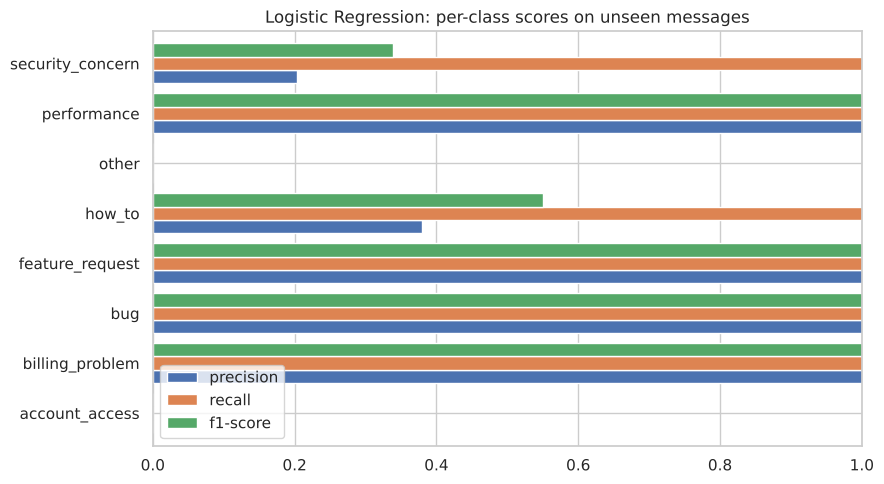

In [10]:
per_class = report.loc[classes, ["precision", "recall", "f1-score"]]
per_class.plot.barh(figsize=(9, 5), width=0.8)
plt.xlim(0, 1); plt.title("Logistic Regression: per-class scores on unseen messages")
plt.tight_layout(); plt.savefig(FIG / "21_per_class_scores.png"); plt.show()

The results split into two groups:

- **Perfect on unseen wording:** billing_problem, bug, feature_request and performance. Their test sentences share key words with training sentences ("error", "add an option", "slow", "billed").
- **Complete misses:** account_access and other score 0. Each has only 3 sentences in total, so the model learned 2 and was tested on a third that uses different words.
- how_to and security_concern have perfect recall but low precision, because they absorb the tickets from the two missed classes.

This is the "hidden imbalance" from notebook 01 showing up: classes with very little variety in wording don't generalise.

### 5.2 Confusion matrix

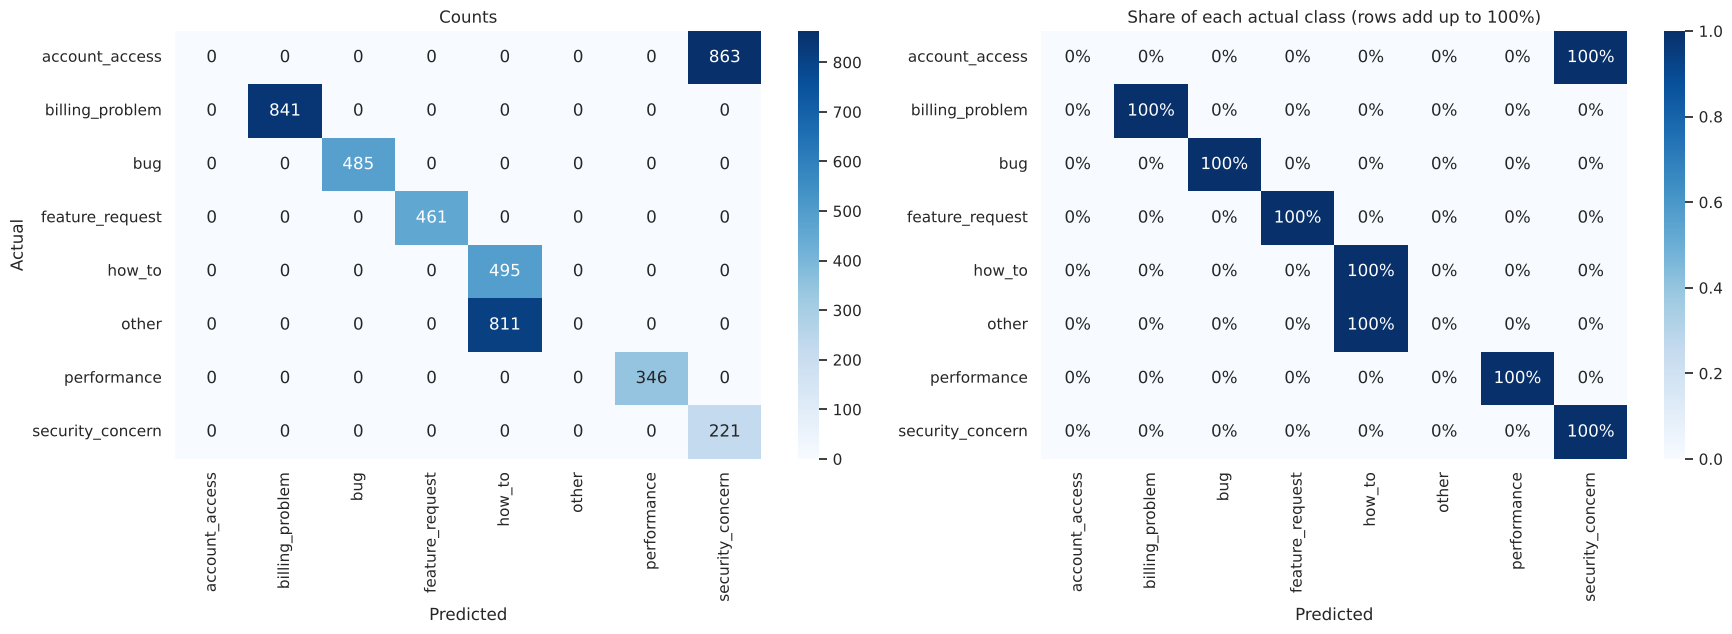

In [11]:
cm = confusion_matrix(y_test, pred, labels=classes)
cm_pct = confusion_matrix(y_test, pred, labels=classes, normalize="true")

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Counts"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
sns.heatmap(cm_pct, annot=True, fmt=".0%", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Share of each actual class (rows add up to 100%)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "22_confusion_matrix.png"); plt.show()

In [12]:
# the most common mistakes, with the messages behind them
mistakes = test[pred != y_test].assign(predicted=pred[pred != y_test])
top_pairs = mistakes.groupby([TARGET, "predicted"]).size().sort_values(ascending=False).head(5)
for (actual, predicted), n in top_pairs.items():
    print(f"\n{actual} predicted as {predicted}: {n} tickets")
    for msg in mistakes[(mistakes[TARGET] == actual) & (mistakes["predicted"] == predicted)][TEXT].unique()[:3]:
        print("   -", msg)


account_access predicted as security_concern: 863 tickets
   - My account was locked after multiple failed login attempts.

other predicted as how_to: 811 tickets
   - I need help but I'm not sure which category this fits in.


Both big mistakes are understandable when you read the sentences:

- "My account was locked after multiple failed login attempts" goes to **security_concern**, because the training data only had "login" in the security sentence "I noticed a suspicious **login** on my account".
- "I need help but I'm not sure which category this fits in" goes to **how_to**, because "I need help setting up..." is a how_to sentence.

The model is matching words, not meaning. More varied training wording, or sentence embeddings that capture meaning, would help these two classes most.

### 5.3 ROC curves and ROC-AUC per class

Macro ROC-AUC: 0.886


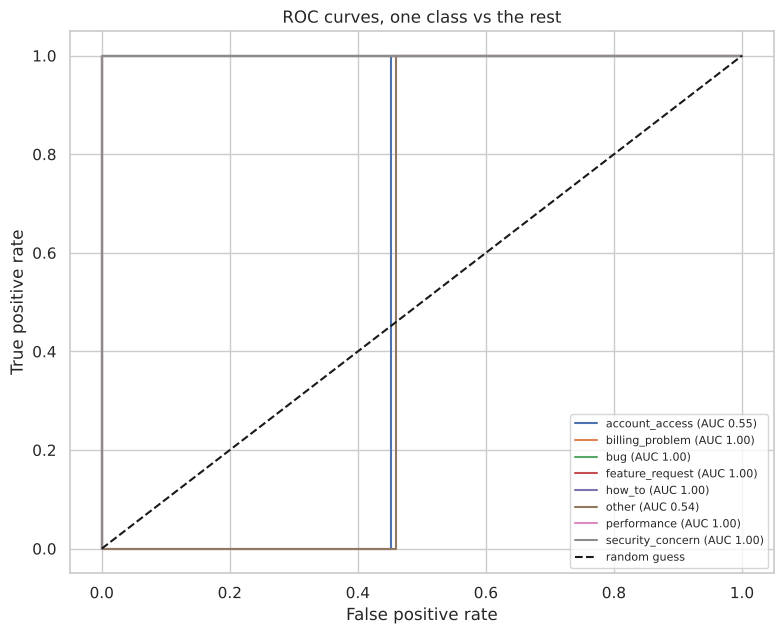

In [13]:
auc_per_class = {}
plt.figure(figsize=(8, 6.5))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
    auc_per_class[c] = roc_auc_score(y_test_bin[:, i], proba[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC {auc_per_class[c]:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, one class vs the rest"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "23_roc_curves.png"); plt.show()

print(f"Macro ROC-AUC: {np.mean(list(auc_per_class.values())):.3f}")

Macro ROC-AUC is 0.89, much better than random (0.5). So even when the top pick is wrong, the right category is usually ranked high.
The two classes with zero F1 have the lowest AUC, which is consistent with the confusion matrix.

### 5.4 Confidence: can the model tell when it's unsure?

The confidence of a prediction is the probability of the top class. If the model is sensible, low-confidence predictions
should be wrong more often. Then we can send them to a person instead of forcing a category (requirement FR-04).

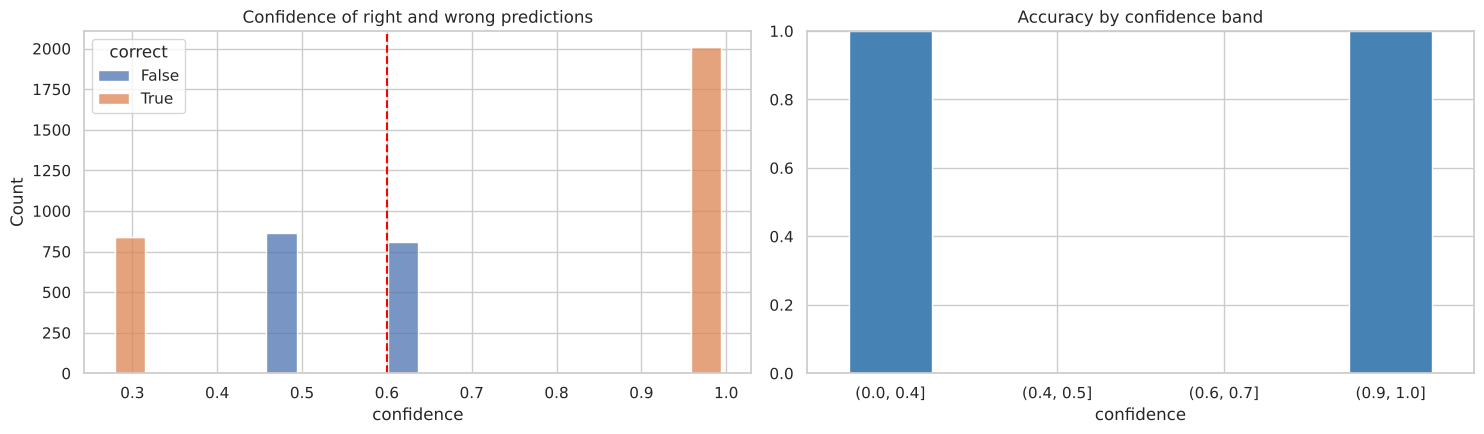

,tickets,accuracy
confidence,,
"(0.0, 0.4]",841,1.000
"(0.4, 0.5]",863,0.000
"(0.6, 0.7]",811,0.000
"(0.9, 1.0]",2008,1.000


In [14]:
conf = proba.max(axis=1)
result = pd.DataFrame({"confidence": conf, "correct": pred == y_test.values})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(data=result, x="confidence", hue="correct", bins=20, multiple="stack", ax=axes[0])
axes[0].axvline(config.CONFIDENCE_THRESHOLD, color="red", ls="--")
axes[0].set_title("Confidence of right and wrong predictions")

bands = pd.cut(result["confidence"], [0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
by_band = result.groupby(bands, observed=True).agg(tickets=("correct", "size"), accuracy=("correct", "mean"))
by_band["accuracy"].plot.bar(ax=axes[1], color="steelblue", rot=0)
axes[1].set_ylim(0, 1); axes[1].set_title("Accuracy by confidence band"); axes[1].set_xlabel("confidence")
plt.tight_layout(); plt.savefig(FIG / "24_confidence.png"); plt.show()
by_band

In [15]:
t = config.CONFIDENCE_THRESHOLD
auto = result[result["confidence"] >= t]
review = result[result["confidence"] < t]
print(f"Threshold {t:.0%}")
print(f"Routed automatically: {len(auto) / len(result):.1%} of tickets, accuracy {auto['correct'].mean():.1%}")
print(f"Sent to manual review: {len(review) / len(result):.1%} of tickets, accuracy {review['correct'].mean():.1%}")

Threshold 60%
Routed automatically: 62.3% of tickets, accuracy 71.2%
Sent to manual review: 37.7% of tickets, accuracy 49.4%


Confidence helps, but it's not perfect. Tickets above the 60% threshold are right 71% of the time, while those below it are right only 49% of the time,
so the review rule does catch a large share of mistakes.

But one fully correct group (billing tickets with new wording) sits at low confidence, and one wrong group (other → how_to) sits at 60–70%.
With only 20 test sentences, each sentence moves a whole bar. In practice, the threshold should be tuned on more varied real tickets.

### 5.5 Worked examples

The brief asks for examples covering a common ticket, an ambiguous one, a minority category and a low-confidence case.
Here we use the model trained on the training messages, so these sentences are new to it (except the first one).

In [16]:
def explain_prediction(model, text):
    p = model.predict_proba([text])[0]
    order = np.argsort(-p)
    top1, top2 = model.classes_[order[0]], model.classes_[order[1]]
    status = "auto-route" if p[order[0]] >= config.CONFIDENCE_THRESHOLD else "MANUAL REVIEW"
    return {"message": text, "predicted": top1, "confidence": round(p[order[0]], 2),
            "runner_up": top2, "runner_up_conf": round(p[order[1]], 2), "decision": status,
            "queue": config.ROUTING[top1] if status == "auto-route" else config.REVIEW_QUEUE}

examples = {
    "common (seen in training)": train_msgs[TEXT].iloc[0],
    "ambiguous": "The billing page is very slow and keeps showing an error.",
    "minority class, new wording": test_msgs.loc[test_msgs[TARGET] == "account_access", TEXT].iloc[0],
    "out of scope": "The coffee machine on the third floor is broken.",
}
pd.DataFrame([{"case": k, **explain_prediction(lr, v)} for k, v in examples.items()])

,case,message,predicted,confidence,runner_up,runner_up_conf,decision,queue
0,common (seen in training),I need help setting up data export for my team.,how_to,0.990,feature_request,0.000,auto-route,Service Desk (L1)
1,ambiguous,The billing page is very slow and keeps showing an error.,performance,0.710,bug,0.200,auto-route,Platform / SRE
2,"minority class, new wording",My account was locked after multiple failed login attempts.,security_concern,0.470,other,0.200,MANUAL REVIEW,Manual Triage
3,out of scope,The coffee machine on the third floor is broken.,bug,0.460,performance,0.170,MANUAL REVIEW,Manual Triage


- **Common:** a known sentence is classified with 99% confidence and routed straight to the Service Desk.
- **Ambiguous:** a message mixing "slow" and "error" goes to performance (71%), with bug as the runner-up. A person might reasonably pick either.
- **Minority class, new wording:** the account-lockout ticket gets only 47% confidence, so it goes to manual review instead of the wrong team. That's the review rule doing its job.
- **Out of scope:** a coffee machine complaint gets 46% confidence and is sent to review rather than forced into a category.

## 6. Save results for the dashboard

**Predictions for every ticket.** The dashboard needs a prediction for all 20,000 tickets. If we used the final model,
it would be predicting messages it was trained on, which is the leakage problem again. So we use **out-of-fold** predictions:
grouped 5-fold cross-validation, where each ticket is predicted by a model that never saw its message.

In [17]:
final_pipeline = make_pipeline(tfidf(), LogisticRegression(max_iter=2000, C=1.0))
oof_proba = cross_val_predict(final_pipeline, X, y, groups=X, cv=cv, method="predict_proba")
oof_classes = np.array(classes)                  # cross_val_predict returns columns in sorted class order
order = np.argsort(-oof_proba, axis=1)

predictions = pd.DataFrame({
    "ticket_id": tickets["ticket_id"],
    "true_category": y,
    "pred_category": oof_classes[order[:, 0]],
    "confidence": oof_proba[np.arange(len(X)), order[:, 0]],
    "second_category": oof_classes[order[:, 1]],
    "second_confidence": oof_proba[np.arange(len(X)), order[:, 1]],
})
predictions["correct"] = predictions["pred_category"] == predictions["true_category"]
predictions["needs_review"] = predictions["confidence"] < config.CONFIDENCE_THRESHOLD
predictions["queue"] = np.where(predictions["needs_review"], config.REVIEW_QUEUE,
                                predictions["pred_category"].map(config.ROUTING))
for i, c in enumerate(classes):
    predictions[f"proba_{c}"] = oof_proba[:, i]

print(f"Out-of-fold macro F1: {f1_score(y, predictions['pred_category'], average='macro'):.3f}")
print(f"Out-of-fold ROC-AUC : {roc_auc_score(label_binarize(y, classes=classes), oof_proba, average='macro'):.3f}")
print(f"Sent to review      : {predictions['needs_review'].mean():.1%}")
predictions.head()

Out-of-fold macro F1: 0.541
Out-of-fold ROC-AUC : 0.862
Sent to review      : 45.7%


,ticket_id,true_category,pred_category,confidence,second_category,second_confidence,correct,needs_review,queue,proba_account_access,proba_billing_problem,proba_bug,proba_feature_request,proba_how_to,proba_other,proba_performance,proba_security_concern
0,TCKT_077009,other,account_access,0.430,feature_request,0.153,False,True,Manual Triage,0.430,0.078,0.071,0.153,0.082,0.039,0.056,0.090
1,TCKT_052709,other,how_to,0.552,bug,0.118,False,True,Manual Triage,0.034,0.054,0.118,0.047,0.552,0.026,0.076,0.093
2,TCKT_078531,feature_request,feature_request,0.988,how_to,0.002,True,False,Product Management,0.001,0.001,0.002,0.988,0.002,0.002,0.002,0.002
3,TCKT_036435,other,how_to,0.552,bug,0.118,False,True,Manual Triage,0.034,0.054,0.118,0.047,0.552,0.026,0.076,0.093
4,TCKT_009100,security_concern,account_access,0.540,bug,0.163,False,True,Manual Triage,0.540,0.055,0.163,0.056,0.075,0.029,0.050,0.031


In [18]:
# overall metrics for the dashboard (from the out-of-fold predictions)
oof_report = pd.DataFrame(classification_report(y, predictions["pred_category"], output_dict=True, zero_division=0)).T
oof_auc = {c: roc_auc_score((y == c).astype(int), oof_proba[:, i]) for i, c in enumerate(classes)}
oof_report.loc[classes, "roc_auc"] = pd.Series(oof_auc)

predictions.to_csv(config.PROCESSED / "predictions.csv", index=False)
oof_report.to_csv(config.PROCESSED / "classification_report.csv")
comparison.to_csv(config.PROCESSED / "model_comparison.csv")
cv_scores.to_csv(config.PROCESSED / "cv_scores.csv")
pd.DataFrame(confusion_matrix(y, predictions["pred_category"], labels=classes), index=classes, columns=classes) \
  .to_csv(config.PROCESSED / "confusion_matrix.csv")

summary = {
    "model": "TF-IDF (1-2 grams) + Logistic Regression",
    "evaluation": "grouped 5-fold cross-validation by message (out-of-fold)",
    "macro_f1": f1_score(y, predictions["pred_category"], average="macro"),
    "weighted_f1": f1_score(y, predictions["pred_category"], average="weighted"),
    "macro_precision": precision_score(y, predictions["pred_category"], average="macro"),
    "macro_recall": recall_score(y, predictions["pred_category"], average="macro"),
    "accuracy": accuracy_score(y, predictions["pred_category"]),
    "roc_auc_macro": float(np.mean(list(oof_auc.values()))),
    "review_share": float(predictions["needs_review"].mean()),
    "confidence_threshold": config.CONFIDENCE_THRESHOLD,
}
json.dump(summary, open(config.PROCESSED / "metrics.json", "w"), indent=2)
summary

{'model': 'TF-IDF (1-2 grams) + Logistic Regression', 'evaluation': 'grouped 5-fold cross-validation by message (out-of-fold)', 'macro_f1': 0.5414479430433057, 'weighted_f1': 0.5411323244210353, 'macro_precision': 0.531165025597993, 'macro_recall': 0.5841409797296421, 'accuracy': 0.5845, 'roc_auc_macro': 0.8615058787794297, 'review_share': 0.45705, 'confidence_threshold': 0.6}

**The final model.** For predicting brand-new tickets we train Logistic Regression on **all** 20,000 tickets
(all 96 messages), because more wording means better coverage. Its quality is the out-of-fold score above.

In [19]:
final_model = final_pipeline.fit(X, y)
joblib.dump(final_model, config.MODELS / "tfidf_logreg.joblib")
print("Saved models/tfidf_logreg.joblib")
print(explain_prediction(final_model, "I was charged twice for my subscription this month."))

Saved models/tfidf_logreg.joblib
{'message': 'I was charged twice for my subscription this month.', 'predicted': 'billing_problem', 'confidence': np.float64(0.99), 'runner_up': 'how_to', 'runner_up_conf': np.float64(0.0), 'decision': 'auto-route', 'queue': 'Billing Operations'}


## Summary

| Item | Result |
|---|---|
| Features | TF-IDF, single words and word pairs |
| Models compared | Majority baseline, Naive Bayes, Linear SVM, Logistic Regression |
| Honest evaluation | Split by message (no sentence in both train and test) + grouped 5-fold CV |
| Random split (leaky) | Macro F1 1.00, misleading |
| Chosen model | Logistic Regression: tied best F1, gives probabilities, easy to explain |
| Out-of-fold macro F1 / weighted F1 | about 0.54 / 0.54 |
| Out-of-fold ROC-AUC (macro) | about 0.86 |
| Weakest classes | account_access and other (only 3 sentences each) |
| Low-confidence rule | Below 60% → manual review; reviewed tickets are much less accurate, so the rule is useful |

**Saved:** `data/processed/predictions.csv` (out-of-fold predictions for all tickets), `classification_report.csv`, `confusion_matrix.csv`,
`model_comparison.csv`, `cv_scores.csv`, `metrics.json`, and the final model `models/tfidf_logreg.joblib`.

**Limitation to mention:** the scores reflect how the model handles *new wording*. With only 96 sentences, that's a tough test.
Real ticket data with more varied wording would very likely score higher.